# 01. Chuẩn hóa dữ liệu WESAD

- Chuyển đổi các thông số cảm biến thô từ WESAD thành các đại lượng chuẩn cùng với dự án

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_colwidth', None)
here = Path.cwd().resolve()
ROOT = next((p for p in [here, *here.parents] if (p / 'ai/requirements.txt').is_file() and (p / 'backend').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Vui lòng mở notebook trong repository ASD-EASE')
sys.path.insert(0, str(ROOT / 'ai'))

DATA_DIR = ROOT / 'ai/data/interim/wesad/normalized-v1'
print('Thư mục dữ liệu chuẩn hóa:', DATA_DIR)

Thư mục dữ liệu chuẩn hóa: D:\Projects\asd-ease\ai\data\interim\wesad\normalized-v1


## 1. Chuẩn hóa thông số cảm biến của dataset

- Đối chiếu giữa tín hiệu gốc của WESAD và thông số chuẩn được dùng trong dự án.

In [2]:
# Đọc trực tiếp cấu hình và thông số chuẩn hóa từ metadata của dataset đã chuẩn hóa
sample_meta_path = DATA_DIR / 'signals/S2/metadata.json'
with open(sample_meta_path, 'r', encoding='utf-8') as f:
    sample_meta = json.load(f)

channels_info = sample_meta['channels']

rows = []
for ch_name, info in channels_info.items():
    rate = info.get('sample_rate_nominal_hz') or info.get('output_rate_hz')
    unit = info.get('unit', '')
    proc = info.get('processing') or info.get('method', '')
    sample_count = info.get('count')
    count_str = f"{sample_count:,}" if sample_count is not None else "Theo cửa sổ (1 Hz)"
    
    # Xác định cảm biến tương ứng
    if 'bvp' in ch_name: sensor = 'BVP'
    elif 'eda' in ch_name: sensor = 'EDA'
    elif 'acc' in ch_name: sensor = 'ACC'
    elif 'hr' in ch_name: sensor = 'HR'
    else: sensor = 'Khác'
    
    rows.append({
        'Kênh tín hiệu': ch_name,
        'Cảm biến': sensor,
        'Tần số chuẩn hóa': f"{rate} Hz",
        'Đơn vị đầu ra': unit,
        'Công thức / Phương pháp xử lý': proc,
        'Số mẫu ghi nhận (S2)': count_str
    })

pd.set_option('display.max_colwidth', None)
df_conversion = pd.DataFrame(rows)
display(df_conversion)

,Kênh tín hiệu,Cảm biến,Tần số chuẩn hóa,Đơn vị đầu ra,Công thức / Phương pháp xử lý,Số mẫu ghi nhận (S2)
0,bvp,BVP,64 Hz,source_arbitrary_units,raw_source,"389,056"
1,eda_us,EDA,4 Hz,microsiemens,raw_source,"24,316"
2,acc_x_ms2,ACC,32 Hz,m/s^2,ACC_div64_times_9.80665,"194,528"
3,acc_y_ms2,ACC,32 Hz,m/s^2,ACC_div64_times_9.80665,"194,528"
4,acc_z_ms2,ACC,32 Hz,m/s^2,ACC_div64_times_9.80665,"194,528"
5,acc_norm_ms2,ACC,32 Hz,m/s^2,ACC_div64_times_9.80665,"194,528"
6,hr_bpm,HR,1 Hz,bpm,causal_SOS_peaks,Theo cửa sổ (1 Hz)


## 2. 15 đối tượng sau chuẩn hóa

- Thống kê thời lượng ghi nhận (phút) và số lượng mẫu của các kênh tín hiệu từ `S2` đến `S17`.

In [3]:
recordings_file = DATA_DIR / 'recordings.jsonl'
rows = []
with open(recordings_file, 'r', encoding='utf-8') as f:
    for line in f:
        meta = json.loads(line)
        sub = meta['subject_id']
        sub_meta = json.loads((DATA_DIR / meta['metadata']).read_text(encoding='utf-8'))
        bvp_count = sub_meta['channels']['bvp']['count']
        duration_min = (bvp_count / 64) / 60
        rows.append({
            'Đối tượng': sub,
            'Thời lượng (phút)': round(duration_min, 1),
            'BVP (64Hz)': bvp_count,
            'EDA (4Hz)': sub_meta['channels']['eda_us']['count'],
            'ACC (32Hz)': sub_meta['channels']['acc_norm_ms2']['count']
        })

df_subjects = pd.DataFrame(rows)
display(df_subjects)
print(f'Tổng thời lượng đo của 15 người: {df_subjects["Thời lượng (phút)"].sum():.1f} phút (~{df_subjects["Thời lượng (phút)"].sum()/60:.1f} giờ)')

,Đối tượng,Thời lượng (phút),BVP (64Hz),EDA (4Hz),ACC (32Hz)
0,S2,101.3,389056,24316,194528
1,S3,108.2,415552,25972,207776
2,S4,107.0,411072,25692,205536
3,S5,104.3,400512,25032,200256
4,S6,117.8,452544,28284,226272
5,S7,87.3,335232,20952,167616
6,S8,91.1,349824,21864,174912
7,S9,87.0,334272,20892,167136
8,S10,91.6,351744,21984,175872
9,S11,87.2,334912,20932,167456


Tổng thời lượng đo của 15 người: 1447.6 phút (~24.1 giờ)


## 3. Phân bố dữ liệu theo nhãn 0 và 1

- Đối chiếu giữa các mã trạng thái gốc của WESAD và 2 nhãn chuẩn hóa đưa vào huấn luyện AI.

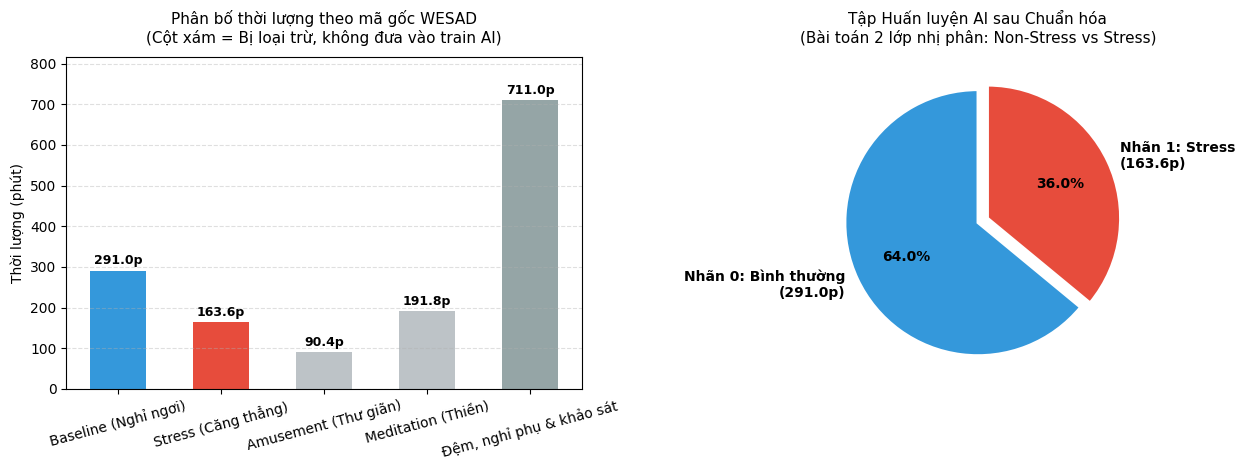

,Mã WESAD,Trạng thái gốc,Chuẩn hóa thành,Đưa vào train AI,Thời lượng (phút)
0,1,Baseline (Nghỉ ngơi),Nhãn 0 (Bình thường),Có,291.0
1,2,Stress (Căng thẳng),Nhãn 1 (Stress),Có,163.6
2,3,Amusement (Thư giãn),Loại trừ,Không,90.4
3,4,Meditation (Thiền),Loại trừ,Không,191.8
4,"0, 5, 6, 7","Đệm, nghỉ phụ & khảo sát",Loại trừ,Không,711.0


In [4]:
verif_file = DATA_DIR / 'verification.json'
verif = json.loads(verif_file.read_text(encoding='utf-8'))

label_config = [
    {'Mã WESAD': '1', 'Trạng thái gốc': 'Baseline (Nghỉ ngơi)', 'Chuẩn hóa thành': 'Nhãn 0 (Bình thường)', 'Đưa vào train AI': 'Có', 'Màu': '#3498DB'},
    {'Mã WESAD': '2', 'Trạng thái gốc': 'Stress (Căng thẳng)', 'Chuẩn hóa thành': 'Nhãn 1 (Stress)', 'Đưa vào train AI': 'Có', 'Màu': '#E74C3C'},
    {'Mã WESAD': '3', 'Trạng thái gốc': 'Amusement (Thư giãn)', 'Chuẩn hóa thành': 'Loại trừ', 'Đưa vào train AI': 'Không', 'Màu': '#BDC3C7'},
    {'Mã WESAD': '4', 'Trạng thái gốc': 'Meditation (Thiền)', 'Chuẩn hóa thành': 'Loại trừ', 'Đưa vào train AI': 'Không', 'Màu': '#BDC3C7'},
    {'Mã WESAD': '0, 5, 6, 7', 'Trạng thái gốc': 'Đệm, nghỉ phụ & khảo sát', 'Chuẩn hóa thành': 'Loại trừ', 'Đưa vào train AI': 'Không', 'Màu': '#95A5A6'}
]

rows = []
for cfg in label_config:
    code = cfg['Mã WESAD']
    if code == '0, 5, 6, 7':
        other_wins = sum(verif['label_coverage'][c]['windows'] for c in ['0', '5', '6', '7', 'mixed'] if c in verif['label_coverage'])
        dur_min = round(other_wins / 60, 1)
    else:
        wins = verif['label_coverage'][code]['windows']
        dur_min = round(wins / 60, 1)
    rows.append({**cfg, 'Thời lượng (phút)': dur_min})

df_labels = pd.DataFrame(rows)

# Trực quan hóa 2 góc nhìn: Toàn bộ mã gốc WESAD vs 2 nhãn train AI
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

# Đồ thị 1: Toàn bộ mã gốc WESAD (Cột xám = Bị loại trừ)
bars = ax1.bar(df_labels['Trạng thái gốc'], df_labels['Thời lượng (phút)'], color=df_labels['Màu'], width=0.55)
ax1.set_ylabel('Thời lượng (phút)', fontsize=10)
ax1.set_title('Phân bố thời lượng theo mã gốc WESAD\n(Cột xám = Bị loại trừ, không đưa vào train AI)', fontsize=11, pad=10)
ax1.tick_params(axis='x', rotation=15)
for bar in bars:
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, y + 8, f'{y:.1f}p', ha='center', va='bottom', fontweight='bold', fontsize=9)
ax1.set_ylim(0, max(df_labels['Thời lượng (phút)']) * 1.15)
ax1.grid(axis='y', linestyle='--', alpha=0.4)

# Đồ thị 2: Tỷ lệ 2 nhãn chuẩn hóa đưa vào train AI
t_base = df_labels.loc[df_labels['Mã WESAD'] == '1', 'Thời lượng (phút)'].values[0]
t_stress = df_labels.loc[df_labels['Mã WESAD'] == '2', 'Thời lượng (phút)'].values[0]
train_times = [t_base, t_stress]
train_labels = [f'Nhãn 0: Bình thường\n({t_base}p)', f'Nhãn 1: Stress\n({t_stress}p)']
train_colors = ['#3498DB', '#E74C3C']
ax2.pie(train_times, labels=train_labels, colors=train_colors, autopct='%1.1f%%', startangle=90, explode=(0, 0.08),
        textprops={'fontsize': 10, 'fontweight': 'bold'}, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
ax2.set_title('Tập Huấn luyện AI sau Chuẩn hóa\n(Bài toán 2 lớp nhị phân: Non-Stress vs Stress)', fontsize=11, pad=10)

plt.tight_layout()
plt.show()

display(df_labels[['Mã WESAD', 'Trạng thái gốc', 'Chuẩn hóa thành', 'Đưa vào train AI', 'Thời lượng (phút)']])